In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input, RepeatVector, TimeDistributed
from tensorflow.keras.optimizers import Adam

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
data = pd.read_csv("NASA TurboFan Engine.csv")

data.head()

,unit,cycle,setting1,setting2,setting3,sensor1,sensor2,sensor3,sensor4,sensor5,...,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21,RUL,Fault_Label
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191,0
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190,0
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189,0
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188,0
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187,0


In [3]:
sensor_cols = [
    "sensor1", "sensor2", "sensor3", "sensor4", "sensor5",
    "sensor6", "sensor7", "sensor8", "sensor9", "sensor10",
    "sensor11", "sensor12", "sensor13", "sensor14", "sensor15",
    "sensor16", "sensor17", "sensor18", "sensor19", "sensor20",
    "sensor21"
]
X = data[sensor_cols].values
y = data["Fault_Label"].values

In [5]:
scaler = StandardScaler()
scaler.fit(X[y==0])
X_scaled = scaler.transform(X)

In [6]:
window_size = 10

X_windows = []
y_windows = []

data_scaled = data.copy()
data_scaled[sensor_cols] = X_scaled

for unit, group in data_scaled.groupby("unit"):
    x = group[sensor_cols].values
    labels = group["Fault_Label"].values

    for i in range(len(x) - window_size + 1):
        X_windows.append(x[i:i + window_size])
        y_windows.append(max(labels[i:i + window_size]))

X_windows = np.array(X_windows)
y_windows = np.array(y_windows)

In [7]:
X_normal = X_windows[y_windows == 0]

trainX, testX = train_test_split(
    X_normal, test_size=0.2, random_state=42
)

print(X_windows.shape)
print(trainX.shape)

(19731, 10, 21)
(13304, 10, 21)


In [8]:
model = Sequential([
    Input(shape=(10, 21)),
    LSTM(32, activation="tanh", return_sequences=True),
    LSTM(16, activation="tanh"),
    RepeatVector(10),
    LSTM(32, activation="tanh", return_sequences=True),
    TimeDistributed(Dense(21))
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 10, 32)              │           6,912 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 16)                  │           3,136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 10, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ (None, 10, 32)              │           6,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 10, 21)              │             693 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 17,013 (66.46 KB)

 Trainable params: 17,013 (66.46 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    trainX, trainX,
    validation_data=(testX, testX),
    batch_size=64,
    epochs=10,
    verbose=1
)

Epoch 1/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.3691 - mae: 0.3858 - val_loss: 0.2940 - val_mae: 0.3373
Epoch 2/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2837 - mae: 0.3321 - val_loss: 0.2778 - val_mae: 0.3281
Epoch 3/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2724 - mae: 0.3254 - val_loss: 0.2695 - val_mae: 0.3223
Epoch 4/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2657 - mae: 0.3202 - val_loss: 0.2645 - val_mae: 0.3182
Epoch 5/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2612 - mae: 0.3171 - val_loss: 0.2601 - val_mae: 0.3161
Epoch 6/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2572 - mae: 0.3149 - val_loss: 0.2571 - val_mae: 0.3135
Epoch 7/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2545 - mae: 0.3132 - val_loss: 0.2544 - val_mae: 0.3126
Epoch 8/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2519 - mae: 0.3123 - val_loss: 0.2519 - val_mae: 0.3116
Epoch 9/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - l

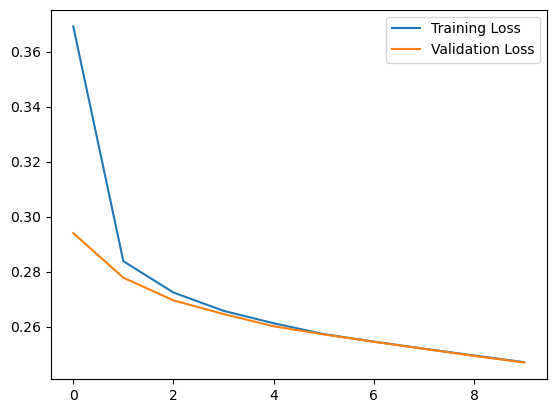

In [10]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.show()

In [11]:
x_test_reconstruct = model.predict(testX, verbose=0)

test_error = np.mean(np.square(testX - x_test_reconstruct),axis=(1, 2))

threshold = np.percentile(test_error, 95)
print("Threshold:", threshold)

Threshold: 0.41567763875928776


In [ ]:

x_reconstruct = model.predict(X_windows, verbose=0)

reconstruction_error = np.mean(np.square(X_windows - x_reconstruct),
    axis=(1, 2)
)

# Predict faults
y_pred = (reconstruction_error > threshold).astype(int)